11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (10000, 784)
Testing data shape: (1000, 784)
Epoch 1/10 | Reconstruction Error: 0.1280 | Free Energy: -76.7442
Epoch 2/10 | Reconstruction Error: 0.0944 | Free Energy: -52.0382
Epoch 3/10 | Reconstruction Error: 0.0890 | Free Energy: -39.4361
Epoch 4/10 | Reconstruction Error: 0.0847 | Free Energy: -35.7633
Epoch 5/10 | Reconstruction Error: 0.0804 | Free Energy: -36.7338
Epoch 6/10 | Reconstruction Error: 0.0767 | Free Energy: -38.6601
Epoch 7/10 | Reconstruction Error: 0.0732 | Free Energy: -41.8745
Epoch 8/10 | Reconstruction Error: 0.0704 | Free Energy: -46.0740
Epoch 9/10 | Reconstruction Error: 0.0681 | Free Energy: -50.7207
Epoch 10/10 | Reconstruction Error: 0.0664 | Free Energy: -54.5760

RBM training completed.


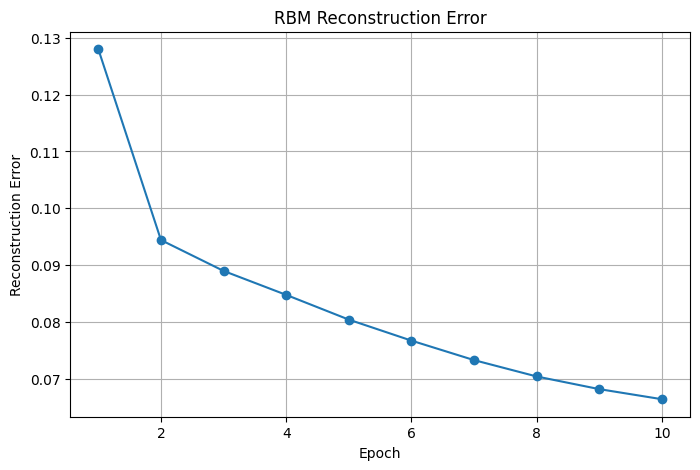

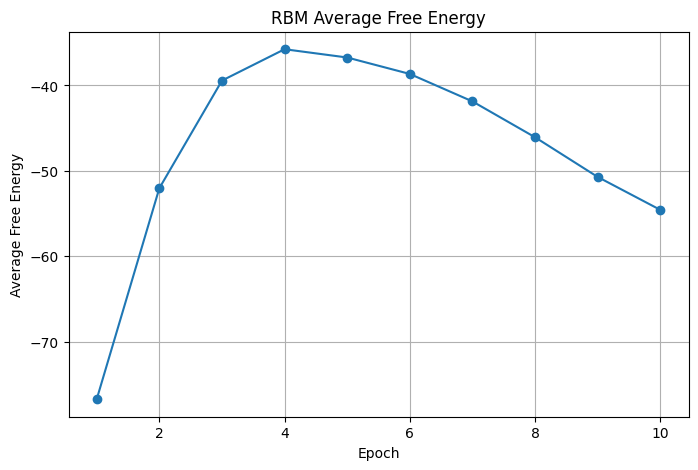

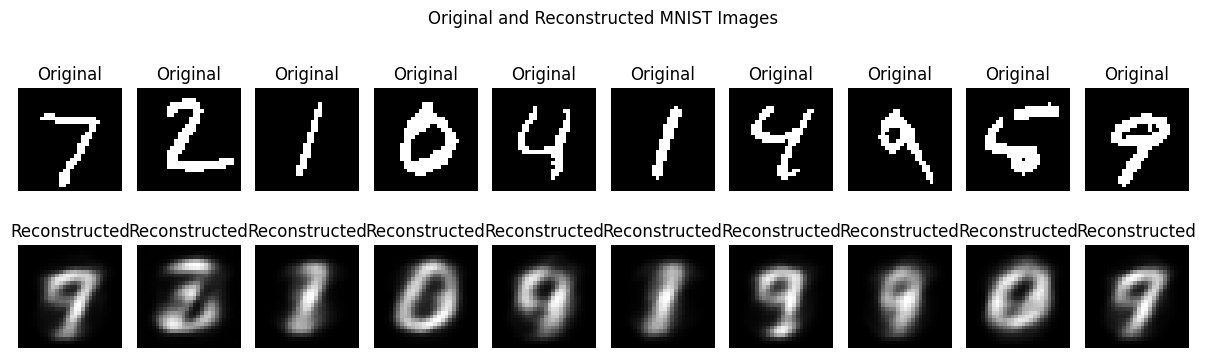


ENERGY OF TEST SAMPLES
Sample 1: Energy = -69.7098
Sample 2: Energy = 1.4311
Sample 3: Energy = -103.3476
Sample 4: Energy = -57.8711
Sample 5: Energy = -65.4976

Experiment 25 completed successfully.
RBM trained using Contrastive Divergence CD-1.
Energy, Free Energy, and Reconstruction Error calculated.


In [29]:

# EXPERIMENT 25: RESTRICTED BOLTZMANN MACHINE (RBM)
# Energy, Training, and Reconstruction using CD-1

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist

# --------------------------------------------------
# STEP 1: LOAD AND PREPROCESS MNIST DATASET
# --------------------------------------------------

(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Use a subset to make training faster
x_train = x_train[:10000]
x_test = x_test[:1000]

# Flatten images from 28x28 into 784 features
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Binarize images
x_train = (x_train > 127).astype(np.float32)
x_test = (x_test > 127).astype(np.float32)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

# --------------------------------------------------
# STEP 2: INITIALIZE RBM
# --------------------------------------------------

n_visible = 784
n_hidden = 64

np.random.seed(42)

W = np.random.normal(0, 0.01, (n_visible, n_hidden))
visible_bias = np.zeros(n_visible)
hidden_bias = np.zeros(n_hidden)

learning_rate = 0.01
epochs = 10
batch_size = 100

# --------------------------------------------------
# STEP 3: SIGMOID FUNCTION
# --------------------------------------------------

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))

# --------------------------------------------------
# STEP 4: HIDDEN AND VISIBLE PROBABILITIES
# --------------------------------------------------

def hidden_probability(v):
    return sigmoid(np.dot(v, W) + hidden_bias)

def visible_probability(h):
    return sigmoid(np.dot(h, W.T) + visible_bias)

# --------------------------------------------------
# STEP 5: RBM ENERGY FUNCTION
# --------------------------------------------------

def energy(v, h):
    return (
        -np.dot(v, visible_bias)
        -np.dot(h, hidden_bias)
        -np.sum(np.dot(v, W) * h, axis=1)
    )

# --------------------------------------------------
# STEP 6: FREE ENERGY FUNCTION
# --------------------------------------------------

def free_energy(v):
    visible_term = -np.dot(v, visible_bias)

    hidden_term = -np.sum(
        np.log1p(np.exp(np.clip(
            np.dot(v, W) + hidden_bias, -500, 500
        ))),
        axis=1
    )

    return visible_term + hidden_term

# --------------------------------------------------
# STEP 7: TRAIN RBM USING CONTRASTIVE DIVERGENCE CD-1
# --------------------------------------------------

reconstruction_errors = []
free_energy_values = []

for epoch in range(epochs):

    np.random.shuffle(x_train)

    epoch_error = 0
    epoch_free_energy = 0
    batches = 0

    for start in range(0, len(x_train), batch_size):

        v0 = x_train[start:start + batch_size]

        if len(v0) == 0:
            continue

        # Positive phase
        ph0 = hidden_probability(v0)
        h0 = (ph0 > np.random.rand(*ph0.shape)).astype(np.float32)

        # Negative phase: one-step Gibbs sampling
        pv1 = visible_probability(h0)
        v1 = (pv1 > np.random.rand(*pv1.shape)).astype(np.float32)

        ph1 = hidden_probability(v1)

        # Update weights and biases
        W += learning_rate * (
            np.dot(v0.T, ph0) - np.dot(v1.T, ph1)
        ) / len(v0)

        visible_bias += learning_rate * np.mean(v0 - v1, axis=0)

        hidden_bias += learning_rate * np.mean(ph0 - ph1, axis=0)

        # Calculate reconstruction error
        epoch_error += np.mean((v0 - pv1) ** 2)

        # Calculate free energy
        epoch_free_energy += np.mean(free_energy(v0))

        batches += 1

    avg_error = epoch_error / batches
    avg_free_energy = epoch_free_energy / batches

    reconstruction_errors.append(avg_error)
    free_energy_values.append(avg_free_energy)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Reconstruction Error: {avg_error:.4f} | "
        f"Free Energy: {avg_free_energy:.4f}"
    )

print("\nRBM training completed.")

# --------------------------------------------------
# STEP 8: PLOT RECONSTRUCTION ERROR
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    reconstruction_errors,
    marker='o'
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Error")
plt.title("RBM Reconstruction Error")
plt.grid(True)

plt.show()

# --------------------------------------------------
# STEP 9: PLOT FREE ENERGY
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    free_energy_values,
    marker='o'
)

plt.xlabel("Epoch")
plt.ylabel("Average Free Energy")
plt.title("RBM Average Free Energy")
plt.grid(True)

plt.show()

# --------------------------------------------------
# STEP 10: RECONSTRUCT TEST IMAGES
# --------------------------------------------------

test_images = x_test[:10]

# Calculate hidden probabilities
hidden_probs = hidden_probability(test_images)

# Convert hidden probabilities to binary states
hidden_states = (
    hidden_probs > np.random.rand(*hidden_probs.shape)
).astype(np.float32)

# Reconstruct visible images
reconstructed_probs = visible_probability(hidden_states)

# Display reconstructed images
plt.figure(figsize=(12, 4))

for i in range(10):

    plt.subplot(2, 10, i + 1)
    plt.imshow(test_images[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_probs[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.suptitle("Original and Reconstructed MNIST Images")
plt.tight_layout()

plt.show()

# --------------------------------------------------
# STEP 11: DISPLAY ENERGY OF SAMPLE
# --------------------------------------------------

sample = test_images[:5]

sample_hidden_prob = hidden_probability(sample)

sample_hidden = (
    sample_hidden_prob > 0.5
).astype(np.float32)

sample_energy = energy(sample, sample_hidden)

print("\nENERGY OF TEST SAMPLES")

for i, value in enumerate(sample_energy):
    print(f"Sample {i + 1}: Energy = {value:.4f}")

# --------------------------------------------------
# STEP 12: FINAL RESULT
# --------------------------------------------------

print("\nExperiment 25 completed successfully.")
print("RBM trained using Contrastive Divergence CD-1.")
print("Energy, Free Energy, and Reconstruction Error calculated.")
